## Imports

In [1]:
import json
import os
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


## Settings

In [2]:
# Visual style settings
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11

APPROACHES_CONFIG = [
    {'det': 'yolov8n', 'trk': 'bytetrack', 'name': 'YOLOv8n + ByteTrack'},
    {'det': 'yolov8n', 'trk': 'botsort', 'name': 'YOLOv8n + BoT-SORT'},
    {'det': 'yolov8s', 'trk': 'bytetrack', 'name': 'YOLOv8s + ByteTrack'},
    {'det': 'yolov8s', 'trk': 'botsort', 'name': 'YOLOv8s + BoT-SORT'},
]

## Paths resolving and preparation

In [3]:
# The split used to aggregate results: 'dev' (default) or 'test'.
# Override without editing the notebook:  SPLIT=test jupyter nbconvert --execute ...
SPLIT = os.environ.get('SPLIT', 'dev')
assert SPLIT in ('dev', 'test'), f'SPLIT must be dev or test, got {SPLIT!r}'


def find_root(start: Path) -> Path:
  """Walk up from `start` to the repository root (the folder with src/ and reports/)."""
  for d in (start, *start.parents):
    if (d / 'src').is_dir() and (d / 'reports').is_dir():
      return d
  raise FileNotFoundError(f'Repository root (with src/ and reports/) not found above {start}')


# Works from the repo root, from scripts/ or from anywhere inside the repo
ROOT_DIR = find_root(Path.cwd().resolve())

reports_dir = ROOT_DIR / 'reports'
tracks_dir = ROOT_DIR / 'outputs' / 'tracks' / SPLIT

# Charts and tables are saved here, file names carry the split
output_dir = reports_dir / 'charts'
output_dir.mkdir(parents=True, exist_ok=True)
print(f'Root: {ROOT_DIR}')
print(f'Split: {SPLIT}')
print(f'Output: {output_dir}')

Root: C:\Users\bobs\Documents\programming\inno\cv\VehicleDetectionAndTrafficCounting
Split: dev
Output: C:\Users\bobs\Documents\programming\inno\cv\VehicleDetectionAndTrafficCounting\reports\charts


## Directoty existence checking

In [4]:
if not reports_dir.exists():
  raise FileNotFoundError(
      f'Detector reports directory "{reports_dir}" not found in the project root, run the evaluation scripts'
  )

if not tracks_dir.exists():
  raise FileNotFoundError(
      f'Tracks directory "{tracks_dir}" not found, run run_tracking.py'
  )

## Tables preparation

In [5]:
rows = []
print(f'Collecting metrics for 4 approaches... Split: {SPLIT.upper()}')

for item in APPROACHES_CONFIG:
  det_name = item['det']
  trk_name = item['trk']
  display_name = item['name']

  # Getting the metrics frop reports
  det_json_path = reports_dir / f'detection_{det_name}_{SPLIT}.json'
  if not det_json_path.exists():
    raise FileNotFoundError(f'Detector report file not found: {det_json_path}, run evaluate_detectors.py for model {det_name}')

  det_data = json.loads(det_json_path.read_text(encoding='utf-8'))

  # Looking for the tracker's timing.json
  matching_dirs = list(tracks_dir.glob(f'{det_name}_{trk_name}_*'))
  if not matching_dirs:
    raise FileNotFoundError(
        f'Tracking results folder not found for the approach "{display_name}" в {tracks_dir}, run run_tracking.py with correspinding arguments'
    )

  # We take the most recent directory if there are several
  target_track_dir = max(matching_dirs, key=lambda p: p.stat().st_mtime)
  timing_file = target_track_dir / 'timing.json'

  if not timing_file.exists():
    raise FileNotFoundError(f'The timing.json file is missing from the directory {target_track_dir}')

  t_data = json.loads(timing_file.read_text(encoding='utf-8'))

  # Metrics evaluation
  map_50 = float(det_data.get('mAP@0.5', 0) or 0) * 100
  map_50_95 = float(det_data.get('mAP@0.5:0.95', 0) or 0) * 100
  fps = float(t_data.get('fps', 0))
  latency_ms = float(t_data.get('total_ms_per_frame', 0))

  rows.append({
      'Approach': display_name,
      'mAP_50': round(map_50, 2),
      'mAP_50_95': round(map_50_95, 2),
      'FPS': round(fps, 2),
      'Latency_ms': round(latency_ms, 2),
  })

df = pd.DataFrame(rows)

# Printing сomparison table
print('\n' + '=' * 65)
print(' ' * 20 + 'Metrics Comparisson Table')
print('=' * 65)
print(df.to_markdown(index=False))


                    Metrics Comparisson Table


| Approach            |   mAP_50 |   mAP_50_95 |    FPS |   Latency_ms |
|:--------------------|---------:|------------:|-------:|-------------:|
| YOLOv8n + ByteTrack |    58.29 |       42.9  | 109.92 |         9.1  |
| YOLOv8n + BoT-SORT  |    58.29 |       42.9  |  67.23 |        14.87 |
| YOLOv8s + ByteTrack |    61.32 |       47.07 |  70.4  |        14.2  |
| YOLOv8s + BoT-SORT  |    61.32 |       47.07 |  48.1  |        20.79 |


## Plots preparatrion


 Charts successfully saved to file: C:\Users\bobs\Documents\programming\inno\cv\VehicleDetectionAndTrafficCounting\reports\charts\models_comparison_charts_dev.png


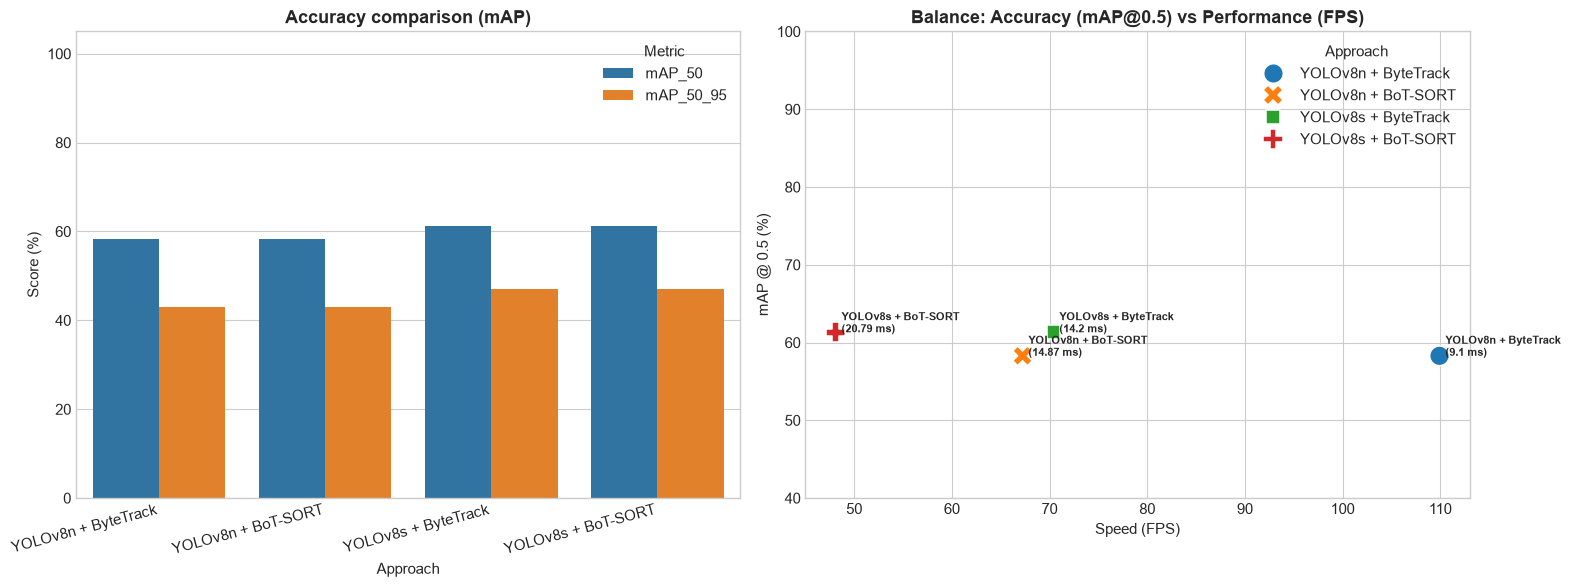

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot for accuracy metrics (mAP@0.5 and mAP@0.5:0.95)
metrics_to_plot = ['mAP_50', 'mAP_50_95']
df_melted = df.melt(
    id_vars='Approach',
    value_vars=metrics_to_plot,
    var_name='Metric',
    value_name='Score (%)',
)

sns.barplot(
    data=df_melted, x='Approach', y='Score (%)', hue='Metric', ax=axes[0]
)
axes[0].set_title('Accuracy comparison (mAP)', fontsize=13, fontweight='bold')
axes[0].set_xticks(range(len(df['Approach'])))
axes[0].set_xticklabels(df['Approach'], rotation=15, ha='right')
axes[0].set_ylim(0, 105)
axes[0].legend(title='Metric')

# График 2: Диаграмма рассеяния Скорость (FPS) vs Качество (mAP@0.5)
sns.scatterplot(
    data=df,
    x='FPS',
    y='mAP_50',
    hue='Approach',
    s=200,
    style='Approach',
    ax=axes[1],
)
axes[1].set_title(
    'Balance: Accuracy (mAP@0.5) vs Performance (FPS)',
    fontsize=13,
    fontweight='bold',
)
axes[1].set_xlabel('Speed (FPS)')
axes[1].set_ylabel('mAP @ 0.5 (%)')
axes[1].set_ylim(40, 100)

# Annotations of points on the graph indicating the delay
for _, row in df.iterrows():
  label_text = f"{row['Approach']}\n({row['Latency_ms']} ms)"
  axes[1].annotate(
      label_text,
      (row['FPS'] + 0.6, row['mAP_50']),
      fontsize=8,
      fontweight='bold',
  )

# Saving the graph to the results folder
plt.tight_layout()

output_img = output_dir / f'models_comparison_charts_{SPLIT}.png'
plt.savefig(output_img, dpi=300, bbox_inches='tight')
print(f'\n Charts successfully saved to file: {output_img}')

plt.show()

## Saving the results

In [7]:
# Saving tables to the results folder
md_path = output_dir / f'metrics_table_{SPLIT}.md'
tex_path = output_dir / f'metrics_table_{SPLIT}.tex'

df.to_markdown(md_path, index=False)
with open(tex_path, 'w', encoding='utf-8') as f:
  f.write(
      df.to_latex(
          index=False,
          float_format='%.2f',
          caption=(
              'Comparison of accuracy and performance for four detection and tracking approaches'
          ),
          label=f'tab:models_comparison_{SPLIT}',
      )
  )

print(f'The tables have been exported to files. "{md_path.name}" and "{tex_path.name}"to the directory "{output_dir}"')

The tables have been exported to files. "metrics_table_dev.md" and "metrics_table_dev.tex"to the directory "C:\Users\bobs\Documents\programming\inno\cv\VehicleDetectionAndTrafficCounting\reports\charts"
